# DepthAnything depth vs. LiDAR — go2nus

Visualizes the metric Video-Depth-Anything depth maps against the RoboSense LiDAR scans, both in 2D (projection onto the image) and in 3D (meshcat, both clouds in the `base_link` frame).

**Run with the `pytorch3d` env** (has meshcat): `mamba run -n pytorch3d jupyter lab`, or register the kernel once with
`mamba run -n pytorch3d python -m ipykernel install --user --name pytorch3d`.

**Data sources** (per-frame index `i` is shared across all modalities — no timestamp matching needed):
- RGB + LiDAR: `$P3D_PROCESSED/go2nus/<traj>/{imgs/<i>.jpg, pcd/<i>.npz}` — LiDAR is `(N,4)` float32 x,y,z,intensity in the `rslidar` frame
- Depth: `$P3D_DEPTH/go2nus/<traj>/depth/<i>.png` — uint16 **millimeters** (metric Video-Depth-Anything vitl, extracted per-frame by `sample_depth_frames.py`; 0/65535 = invalid/clipped)
- Intrinsics: `$P3D_PROCESSED/intrinsics/go2nus/intrinsics.txt` (RealSense D435i color, 848×480)
- Extrinsics: `$P3D_PROCESSED/extrinsics/go2nus/<traj>/extrinsics.txt` = `cam_T_base` (camera_color_optical_frame ← base_link), **per-session pitch fix already baked in**

**Transform chain**: `cam_T_lidar = cam_T_base @ base_T_lidar`, where `base_T_lidar` is the static `base_link → rslidar` transform (translation `[0.14543, 0, 0.13312]`, identity rotation, from `data/go2nus/static_transforms.yaml`).

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import meshcat
import meshcat.geometry as g
import meshcat.transformations as tf

# ---------------- config ----------------
DATA_ROOT = os.path.expandvars('$P3D_PROCESSED/go2nus')
DEPTH_ROOT = os.path.expandvars('$P3D_DEPTH/go2nus')
INTRINSICS_FILE = os.path.expandvars('$P3D_PROCESSED/intrinsics/go2nus/intrinsics.txt')
EXTRINSICS_ROOT = os.path.expandvars('$P3D_PROCESSED/extrinsics/go2nus')
MAX_RANGE = 30.0     # m, ignore lidar returns beyond this for the comparison
MIN_Z_CAM = 0.3      # m, drop points this close to / behind the camera
IMG_W, IMG_H = 848, 480

In [2]:
vis = meshcat.Visualizer()
print('meshcat url:', vis.url())

You can open the visualizer by visiting the following URL:
http://127.0.0.1:7000/static/
meshcat url: http://127.0.0.1:7000/static/


In [11]:
TRAJ = 'deck_1_without_overhead_2025-03-26_12-05-52_1_corrected_merged_0'
FRAME = 11

In [12]:
# ---------------- calibration ----------------
K = np.loadtxt(INTRINSICS_FILE, delimiter=',').reshape(3, 3)

# camera_color_optical_frame <- base_link (pitch fix included)
cam_T_base = np.loadtxt(os.path.join(EXTRINSICS_ROOT, TRAJ, 'extrinsics.txt')).reshape(4, 4)
base_T_cam = np.linalg.inv(cam_T_base)

# base_link <- rslidar (static_transforms.yaml)
base_T_lidar = np.eye(4)
base_T_lidar[:3, 3] = [0.14543, 0.0, 0.13312]

cam_T_lidar = cam_T_base @ base_T_lidar

pitch_deg = np.degrees(np.arcsin(cam_T_base[1, 0]))
print(f'K =\n{K}')
print(f'\ncam_T_lidar =\n{np.round(cam_T_lidar, 4)}')
print(f'\nsession pitch fix: {pitch_deg:.1f} deg')
print(f'camera position in base_link: {np.round(base_T_cam[:3, 3], 4)}')

K =
[[607.65338135   0.         420.5920105 ]
 [  0.         607.36883545 247.97695923]
 [  0.           0.           1.        ]]

cam_T_lidar =
[[ 0.     -1.      0.      0.03  ]
 [ 0.2181  0.     -0.9759 -0.0701]
 [ 0.9759  0.      0.2181 -0.1755]
 [ 0.      0.      0.      1.    ]]

session pitch fix: 12.6 deg
camera position in base_link: [0.332 0.03  0.103]


In [13]:
# ---------------- per-frame loading ----------------
def load_frame(traj, i):
    rgb = np.array(Image.open(os.path.join(DATA_ROOT, traj, 'imgs', f'{i}.jpg')))
    depth_mm = np.array(Image.open(os.path.join(DEPTH_ROOT, traj, 'depth', f'{i}.png')))
    assert depth_mm.dtype == np.uint16
    depth_m = depth_mm.astype(np.float32) / 1000.0
    depth_m[(depth_mm == 0) | (depth_mm == 65535)] = np.nan
    lidar = np.load(os.path.join(DATA_ROOT, traj, 'pcd', f'{i}.npz'))['arr_0']  # (N,4) xyzi, rslidar frame
    return rgb, depth_m, lidar

def project_lidar(lidar_xyz, cam_T_lidar, K):
    """LiDAR points -> pixel coords + z-depth in camera frame.
    Returns (uv (M,2) int, z (M,), pts_cam (M,3)) for points in front of the camera and in bounds."""
    pts_cam = (cam_T_lidar[:3, :3] @ lidar_xyz.T).T + cam_T_lidar[:3, 3]
    z = pts_cam[:, 2]
    keep = z > MIN_Z_CAM
    pts_cam = pts_cam[keep]
    z = z[keep]
    u = K[0, 0] * pts_cam[:, 0] / z + K[0, 2]
    v = K[1, 1] * pts_cam[:, 1] / z + K[1, 2]
    inb = (u >= 0) & (u < IMG_W) & (v >= 0) & (v < IMG_H) & (z < MAX_RANGE)
    uv = np.stack([u[inb], v[inb]], axis=1).astype(int)
    return uv, z[inb], pts_cam[inb]

rgb, depth_m, lidar = load_frame(TRAJ, FRAME)
uv, lidar_z, lidar_cam = project_lidar(lidar[:, :3], cam_T_lidar, K)
n_frames = len(os.listdir(os.path.join(DATA_ROOT, TRAJ, 'imgs')))
print(f'{TRAJ}: {n_frames} frames')
print(f'frame {FRAME}: {lidar.shape[0]} lidar pts, {len(uv)} project into the image')
print(f'DA depth range: {np.nanmin(depth_m):.2f} .. {np.nanmax(depth_m):.2f} m')

deck_1_without_overhead_2025-03-26_12-05-52_1_corrected_merged_0: 149 frames
frame 11: 60398 lidar pts, 8106 project into the image
DA depth range: 2.03 .. 20.89 m


## 2D: LiDAR projected onto RGB vs. DepthAnything map

Both panels share the same colormap and range, so colors are directly comparable. If the calibration is good, lidar dots should sit on the objects they hit and their colors should match the DA map underneath.

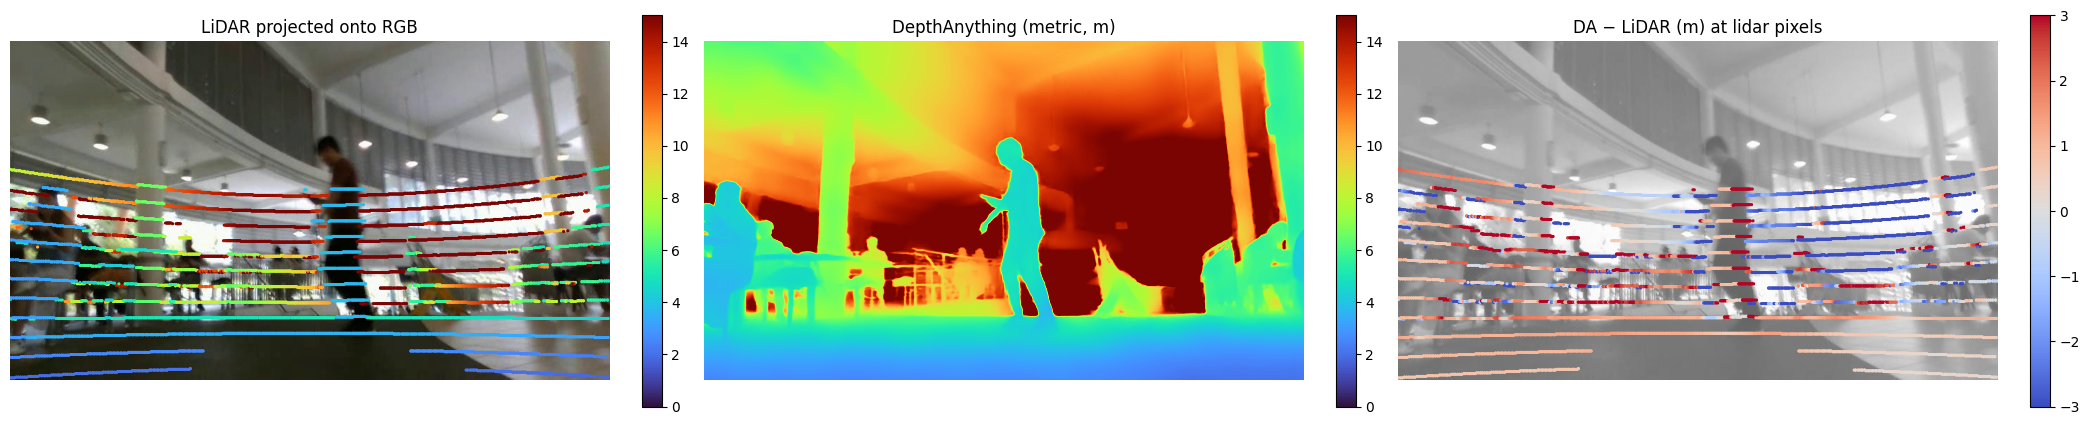

In [14]:
def show_2d(rgb, depth_m, uv, lidar_z, vmax=15.0):
    fig, axes = plt.subplots(1, 3, figsize=(21, 5))
    axes[0].imshow(rgb)
    sc = axes[0].scatter(uv[:, 0], uv[:, 1], c=lidar_z, s=1.5, cmap='turbo', vmin=0, vmax=vmax)
    axes[0].set_title('LiDAR projected onto RGB')
    im = axes[1].imshow(depth_m, cmap='turbo', vmin=0, vmax=vmax)
    axes[1].set_title('DepthAnything (metric, m)')
    # signed error at lidar pixels, on top of a dim rgb
    da_at_lidar = depth_m[uv[:, 1], uv[:, 0]]
    err = da_at_lidar - lidar_z
    axes[2].imshow(rgb.mean(axis=2), cmap='gray', alpha=0.6)
    sc2 = axes[2].scatter(uv[:, 0], uv[:, 1], c=err, s=1.5, cmap='coolwarm', vmin=-3, vmax=3)
    axes[2].set_title('DA − LiDAR (m) at lidar pixels')
    for ax in axes:
        ax.set_xlim(0, IMG_W); ax.set_ylim(IMG_H, 0); ax.axis('off')
    fig.colorbar(sc, ax=axes[0], fraction=0.03)
    fig.colorbar(im, ax=axes[1], fraction=0.03)
    fig.colorbar(sc2, ax=axes[2], fraction=0.03)
    plt.tight_layout(); plt.show()

show_2d(rgb, depth_m, uv, lidar_z)

## Quantitative: DA depth vs. LiDAR z-depth at lidar pixels

n=8106  AbsRel=0.361  RMSE=4.31 m  delta<1.25=52.4%
median(lidar/DA) scale ratio = 0.876  (1.0 = DA is scale-correct)


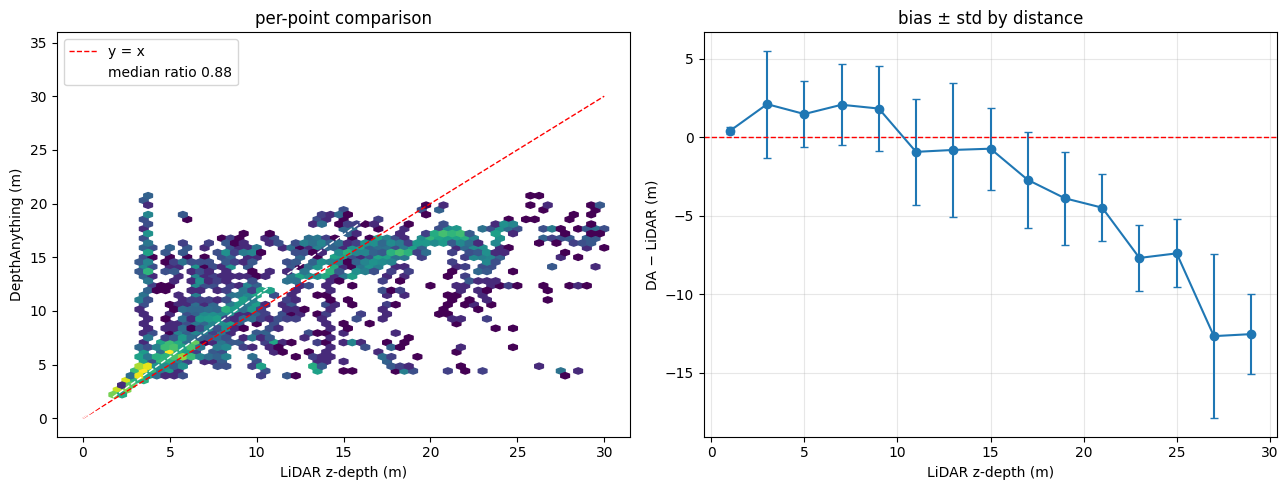

In [17]:
def compare(depth_m, uv, lidar_z):
    da = depth_m[uv[:, 1], uv[:, 0]]
    ok = np.isfinite(da) & (lidar_z > MIN_Z_CAM)
    da, lz = da[ok], lidar_z[ok]
    return da, lz

da, lz = compare(depth_m, uv, lidar_z)
abs_rel = np.mean(np.abs(da - lz) / lz)
rmse = np.sqrt(np.mean((da - lz) ** 2))
ratio = np.median(lz / da)
d125 = np.mean(np.maximum(da / lz, lz / da) < 1.25)
print(f'n={len(da)}  AbsRel={abs_rel:.3f}  RMSE={rmse:.2f} m  delta<1.25={d125:.1%}')
print(f'median(lidar/DA) scale ratio = {ratio:.3f}  (1.0 = DA is scale-correct)')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hexbin(lz, da, gridsize=60, cmap='viridis', bins='log', extent=(0, MAX_RANGE, 0, MAX_RANGE))
axes[0].plot([0, MAX_RANGE], [0, MAX_RANGE], 'r--', lw=1, label='y = x')
axes[0].plot([0, MAX_RANGE], [0, MAX_RANGE / ratio], 'w--', lw=1, label=f'median ratio {ratio:.2f}')
axes[0].set_xlabel('LiDAR z-depth (m)'); axes[0].set_ylabel('DepthAnything (m)')
axes[0].set_title('per-point comparison'); axes[0].legend()

# error binned by distance
bins = np.arange(0, MAX_RANGE + 2, 2)
idx = np.digitize(lz, bins) - 1
centers, means, stds = [], [], []
for b in range(len(bins) - 1):
    m = idx == b
    if m.sum() > 20:
        centers.append(0.5 * (bins[b] + bins[b + 1]))
        means.append(np.mean(da[m] - lz[m]))
        stds.append(np.std(da[m] - lz[m]))
axes[1].errorbar(centers, means, yerr=stds, fmt='o-', capsize=3)
axes[1].axhline(0, color='r', ls='--', lw=1)
axes[1].set_xlabel('LiDAR z-depth (m)'); axes[1].set_ylabel('DA − LiDAR (m)')
axes[1].set_title('bias ± std by distance'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3D: meshcat

Both clouds in the `base_link` frame (x forward, z up):
- `da_cloud` — DA depth unprojected through K, colored with the RGB image
- `lidar_cloud` — raw scan, green (front hemisphere within `MAX_RANGE`; set `full_scan=True` for the whole 360°)

Open the printed URL in a browser. Toggle clouds on/off in the meshcat *Scene* tree to compare surfaces — misalignment shows up as double walls / floating floors.

In [18]:
def depth_to_cloud(depth_m, rgb, K, base_T_cam, stride=2, max_range=MAX_RANGE):
    """Unproject DA depth to a colored cloud in base_link frame. Returns (3,N) pos, (3,N) rgb01."""
    H, W = depth_m.shape
    v, u = np.mgrid[0:H:stride, 0:W:stride]
    z = depth_m[v, u]
    ok = np.isfinite(z) & (z > 0) & (z < max_range)
    u, v, z = u[ok], v[ok], z[ok]
    x = (u - K[0, 2]) * z / K[0, 0]
    y = (v - K[1, 2]) * z / K[1, 1]
    pts_cam = np.stack([x, y, z], axis=1)
    pts_base = (base_T_cam[:3, :3] @ pts_cam.T).T + base_T_cam[:3, 3]
    colors = rgb[v, u].astype(np.float32).T / 255.0
    return pts_base.T.astype(np.float32), colors

def lidar_to_cloud(lidar_xyz, base_T_lidar, cam_T_lidar, full_scan=False, max_range=MAX_RANGE):
    """LiDAR scan -> (3,N) positions in base_link frame. By default keep only points in front of the camera."""
    r = np.linalg.norm(lidar_xyz, axis=1)
    keep = r < max_range
    if not full_scan:
        z_cam = (cam_T_lidar[:3, :3] @ lidar_xyz.T).T[:, 2] + cam_T_lidar[2, 3]
        keep &= z_cam > MIN_Z_CAM
    pts = lidar_xyz[keep]
    pts_base = (base_T_lidar[:3, :3] @ pts.T).T + base_T_lidar[:3, 3]
    return pts_base.T.astype(np.float32)

def draw_axes(vis, name='base_link', length=0.5):
    for axis, color in zip(np.eye(3), [0xff0000, 0x00ff00, 0x0000ff]):
        seg = np.zeros((3, 2), dtype=np.float32); seg[:, 1] = axis * length
        vis[f'{name}/axis_{color:06x}'].set_object(
            g.LineSegments(g.PointsGeometry(seg), g.LineBasicMaterial(color=color)))

def show_meshcat(traj, i, apply_scale=False, full_scan=False, stride=2, show_lidar=True):
    rgb, depth_m, lidar = load_frame(traj, i)
    d = depth_m.copy()
    if apply_scale:  # align DA to lidar with the median scale ratio from this frame
        uv_, lz_, _ = project_lidar(lidar[:, :3], cam_T_lidar, K)
        da_, lzk_ = compare(d, uv_, lz_)
        d *= np.median(lzk_ / da_)
    pos, col = depth_to_cloud(d, rgb, K, base_T_cam, stride=stride)
    vis['da_cloud'].set_object(g.PointCloud(pos, col, size=0.03))
    if show_lidar:
        lpos = lidar_to_cloud(lidar[:, :3], base_T_lidar, cam_T_lidar, full_scan=full_scan)
        lcol = np.tile(np.array([[0.1], [1.0], [0.2]], dtype=np.float32), (1, lpos.shape[1]))
        vis['lidar_cloud'].set_object(g.PointCloud(lpos, lcol, size=0.04))
        n_lidar = lpos.shape[1]
    else:
        vis['lidar_cloud'].delete()
        n_lidar = 0
    draw_axes(vis)
    print(f'frame {i}: DA cloud {pos.shape[1]} pts, lidar {n_lidar} pts'
          + (f', scale applied' if apply_scale else ''))

show_meshcat(TRAJ, FRAME)

frame 11: DA cloud 101760 pts, lidar 25138 pts


### Step through frames / try scale alignment

- `show_meshcat(TRAJ, i)` — any frame
- `show_meshcat(TRAJ, i, show_lidar=False)` — RGB-colored depth cloud alone (no lidar overlay)
- `show_meshcat(TRAJ, i, stride=1)` — full-resolution RGB cloud (~400k pts; default stride=2 is ~100k)
- `show_meshcat(TRAJ, i, apply_scale=True)` — rescale DA by this frame's median lidar/DA ratio before unprojecting (isolates *shape* error from *scale* error)
- `show_meshcat(TRAJ, i, full_scan=True)` — full 360° lidar scan instead of only the camera frustum

In [19]:
# example: a later frame with per-frame scale alignment
# show_meshcat(TRAJ, min(50, n_frames - 1), apply_scale=True)

### Aggregate over a trajectory (optional)

Per-frame scale ratio and AbsRel across the whole trajectory — useful to see whether the DA scale drifts over time or is consistently off.

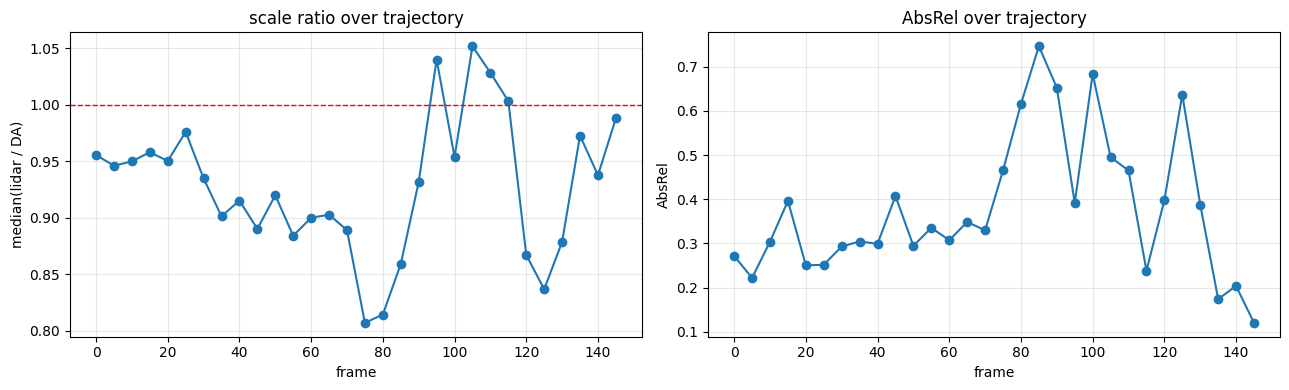

trajectory median scale ratio: 0.933, median AbsRel: 0.333


In [20]:
def traj_stats(traj, step=5):
    frames, ratios, absrels = [], [], []
    for i in range(0, n_frames, step):
        try:
            _, d, l = load_frame(traj, i)
        except FileNotFoundError:
            continue
        uv_, lz_, _ = project_lidar(l[:, :3], cam_T_lidar, K)
        da_, lzk_ = compare(d, uv_, lz_)
        if len(da_) < 100:
            continue
        frames.append(i)
        ratios.append(np.median(lzk_ / da_))
        absrels.append(np.mean(np.abs(da_ - lzk_) / lzk_))
    return np.array(frames), np.array(ratios), np.array(absrels)

frames, ratios, absrels = traj_stats(TRAJ)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(frames, ratios, 'o-'); axes[0].axhline(1.0, color='r', ls='--', lw=1)
axes[0].set_xlabel('frame'); axes[0].set_ylabel('median(lidar / DA)'); axes[0].set_title('scale ratio over trajectory')
axes[1].plot(frames, absrels, 'o-')
axes[1].set_xlabel('frame'); axes[1].set_ylabel('AbsRel'); axes[1].set_title('AbsRel over trajectory')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f'trajectory median scale ratio: {np.median(ratios):.3f}, median AbsRel: {np.median(absrels):.3f}')

## VGGT-Omega comparison

Depths from [VGGT-Omega](https://github.com/facebookresearch/vggt-omega) (1B @ 512), generated per trajectory with `run_vggt_omega.py` (run it with the **calib** env — torch 2.6):

```bash
$P3D_CONDA_ENVS/calib/bin/python run_vggt_omega.py --traj <traj_name>
```

That saves `<DEPTH_ROOT>/<traj>/vggt_omega_depth.npz`: `depths (T, 384, 688)` float16 at model resolution (848×480 is resized to 688×384, so mapping back is a plain resize), `conf`, VGGT-predicted cameras, and `chunk_id` (frames are inferred jointly in chunks of 24).

**Unlike the DA depths, VGGT-Omega depth is up-to-scale** — each chunk has its own arbitrary scene scale. All comparisons below therefore align VGGT to lidar with a per-frame median scale first; for fairness the DA numbers are shown both raw (metric) and scale-aligned.

In [21]:
import cv2

# ---------------- VGGT-Omega loading ----------------
vggt = np.load(os.path.join(DEPTH_ROOT, TRAJ, 'vggt_omega_depth.npz'))
print({k: (vggt[k].shape, str(vggt[k].dtype)) for k in vggt.files})

def load_vggt_frame(i, conf_pct=None):
    """VGGT depth for frame i, resized to native 848x480, raw (chunk-local) scale.
    conf_pct: if set, drop pixels below this confidence percentile."""
    d = cv2.resize(vggt['depths'][i].astype(np.float32), (IMG_W, IMG_H), interpolation=cv2.INTER_LINEAR)
    d[d <= 0] = np.nan
    if conf_pct is not None:
        c = cv2.resize(vggt['conf'][i].astype(np.float32), (IMG_W, IMG_H), interpolation=cv2.INTER_LINEAR)
        d[c < np.nanpercentile(c, conf_pct)] = np.nan
    return d

def lidar_scale(depth, uv, lidar_z):
    """Median lidar/depth ratio at lidar pixels (aligns an up-to-scale map to metric)."""
    d, lz = compare(depth, uv, lidar_z)
    return np.median(lz / d) if len(d) else np.nan

vggt_raw = load_vggt_frame(FRAME)
s_vggt = lidar_scale(vggt_raw, uv, lidar_z)
vggt_m = vggt_raw * s_vggt
print(f'frame {FRAME}: VGGT scale (lidar-aligned) = {s_vggt:.3f}, '
      f'scaled range {np.nanmin(vggt_m):.2f} .. {np.nanmax(vggt_m):.2f} m')

{'depths': ((149, 384, 688), 'float16'), 'conf': ((149, 384, 688), 'float16'), 'extrinsics': ((149, 3, 4), 'float32'), 'intrinsics': ((149, 3, 3), 'float32'), 'chunk_id': ((149,), 'int16')}
frame 11: VGGT scale (lidar-aligned) = 12.885, scaled range 1.87 .. 23.61 m


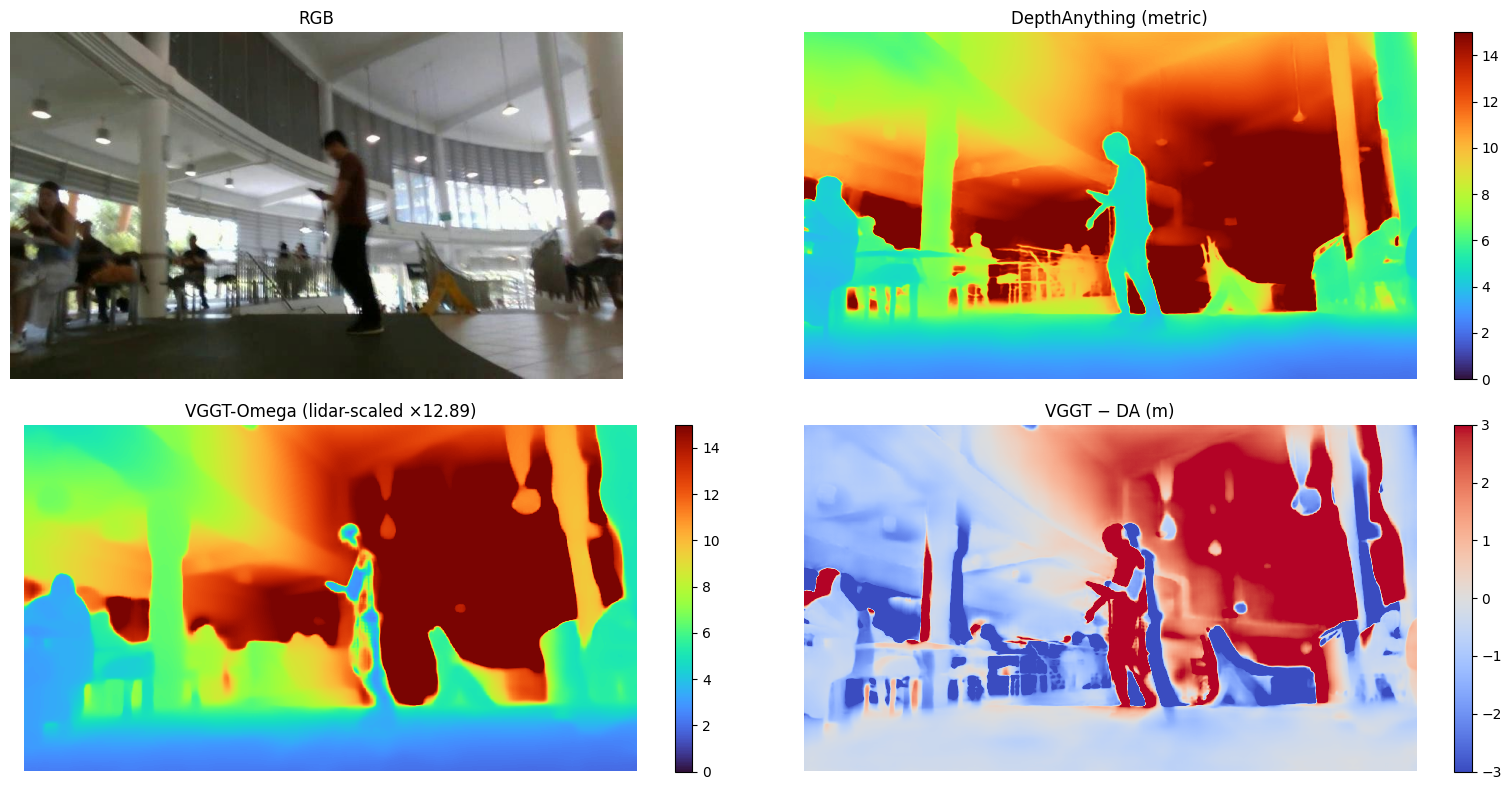

DA (raw metric)              AbsRel=0.361  RMSE=4.31 m  delta<1.25=52.4%  (n=8106)
DA (scale-aligned x0.88)     AbsRel=0.296  RMSE=4.58 m  delta<1.25=61.4%  (n=8106)
VGGT (scale-aligned x12.89)  AbsRel=0.226  RMSE=3.61 m  delta<1.25=75.7%  (n=8106)


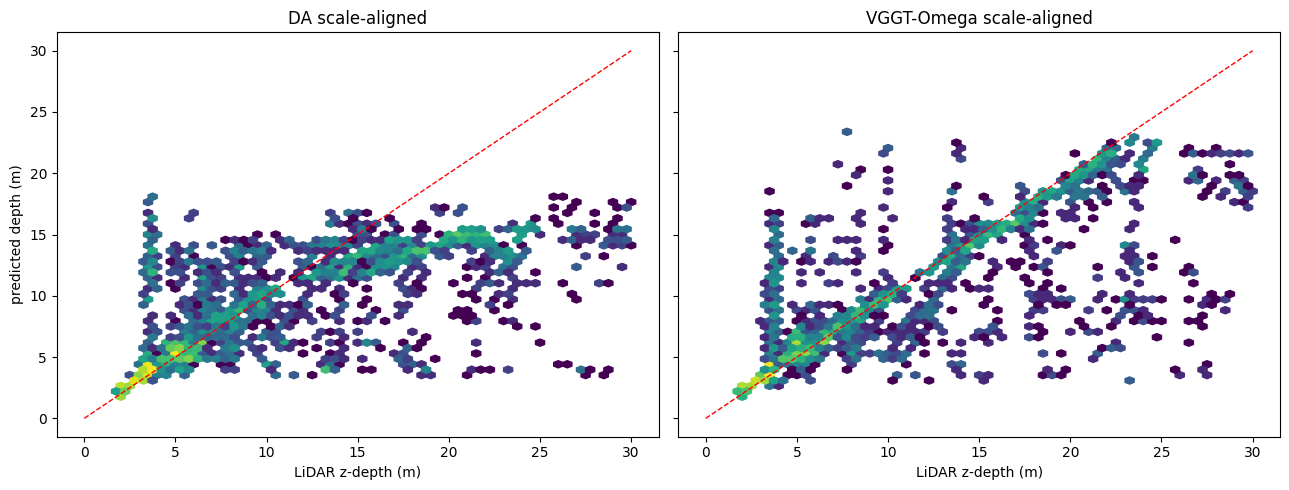

In [22]:
# ---------------- 2D: DA vs VGGT-Omega, same colormap/range ----------------
def stats_line(name, depth, uv, lidar_z, scale=1.0):
    d, lz = compare(depth * scale, uv, lidar_z)
    abs_rel = np.mean(np.abs(d - lz) / lz)
    rmse = np.sqrt(np.mean((d - lz) ** 2))
    d125 = np.mean(np.maximum(d / lz, lz / d) < 1.25)
    print(f'{name:28s} AbsRel={abs_rel:.3f}  RMSE={rmse:.2f} m  delta<1.25={d125:.1%}  (n={len(d)})')
    return d, lz

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
vmax = 15.0
axes[0, 0].imshow(rgb); axes[0, 0].set_title('RGB')
im = axes[0, 1].imshow(depth_m, cmap='turbo', vmin=0, vmax=vmax)
axes[0, 1].set_title('DepthAnything (metric)')
axes[1, 0].imshow(vggt_m, cmap='turbo', vmin=0, vmax=vmax)
axes[1, 0].set_title(f'VGGT-Omega (lidar-scaled ×{s_vggt:.2f})')
diff = vggt_m - depth_m
imd = axes[1, 1].imshow(diff, cmap='coolwarm', vmin=-3, vmax=3)
axes[1, 1].set_title('VGGT − DA (m)')
for ax in axes.ravel(): ax.axis('off')
fig.colorbar(im, ax=axes[0, 1], fraction=0.03); fig.colorbar(im, ax=axes[1, 0], fraction=0.03)
fig.colorbar(imd, ax=axes[1, 1], fraction=0.03)
plt.tight_layout(); plt.show()

s_da = lidar_scale(depth_m, uv, lidar_z)
stats_line('DA (raw metric)', depth_m, uv, lidar_z)
stats_line(f'DA (scale-aligned x{s_da:.2f})', depth_m, uv, lidar_z, scale=s_da)
da_v, lz_v = stats_line(f'VGGT (scale-aligned x{s_vggt:.2f})', vggt_raw, uv, lidar_z, scale=s_vggt)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (d_, name) in zip(axes, [(compare(depth_m * s_da, uv, lidar_z), f'DA scale-aligned'),
                                 ((da_v, lz_v), 'VGGT-Omega scale-aligned')]):
    dd, ll = d_
    ax.hexbin(ll, dd, gridsize=60, cmap='viridis', bins='log', extent=(0, MAX_RANGE, 0, MAX_RANGE))
    ax.plot([0, MAX_RANGE], [0, MAX_RANGE], 'r--', lw=1)
    ax.set_xlabel('LiDAR z-depth (m)'); ax.set_title(name)
axes[0].set_ylabel('predicted depth (m)')
plt.tight_layout(); plt.show()

In [23]:
# ---------------- meshcat: three-way ----------------
# adds an RGB-colored `vggt_cloud` next to `da_cloud` and `lidar_cloud`;
# toggle each in the Scene tree. VGGT is always lidar-scale-aligned per frame.
def show_meshcat_all(traj, i, stride=2, show_lidar=True, conf_pct=None):
    rgb, depth_m, lidar = load_frame(traj, i)
    uv_, lz_, _ = project_lidar(lidar[:, :3], cam_T_lidar, K)

    pos, col = depth_to_cloud(depth_m, rgb, K, base_T_cam, stride=stride)
    vis['da_cloud'].set_object(g.PointCloud(pos, col, size=0.03))

    vraw = load_vggt_frame(i, conf_pct=conf_pct)
    s = lidar_scale(vraw, uv_, lz_)
    vpos, vcol = depth_to_cloud(vraw * s, rgb, K, base_T_cam, stride=stride)
    vis['vggt_cloud'].set_object(g.PointCloud(vpos, vcol, size=0.03))

    if show_lidar:
        lpos = lidar_to_cloud(lidar[:, :3], base_T_lidar, cam_T_lidar)
        lcol = np.tile(np.array([[0.1], [1.0], [0.2]], dtype=np.float32), (1, lpos.shape[1]))
        vis['lidar_cloud'].set_object(g.PointCloud(lpos, lcol, size=0.04))
    else:
        vis['lidar_cloud'].delete()
    draw_axes(vis)
    print(f'frame {i}: da {pos.shape[1]} pts, vggt {vpos.shape[1]} pts (scale x{s:.2f})')

show_meshcat_all(TRAJ, FRAME)

frame 11: da 101760 pts, vggt 101760 pts (scale x12.89)


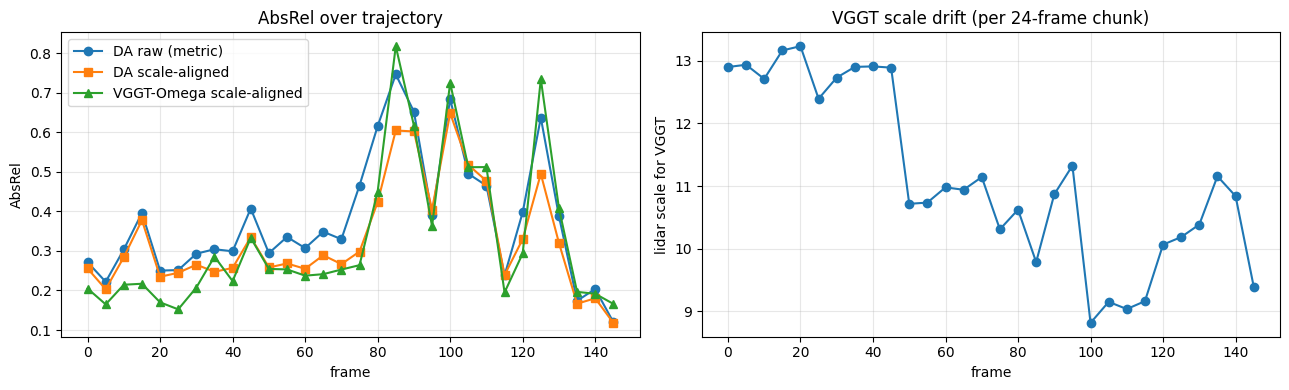

median AbsRel — DA raw: 0.333, DA aligned: 0.276, VGGT aligned: 0.253


In [ ]:
# ---------------- aggregate over the trajectory: DA vs VGGT ----------------
def traj_stats_both(traj, step=5):
    rows = []
    for i in range(0, min(n_frames, vggt['depths'].shape[0]), step):
        try:
            _, d, l = load_frame(traj, i)
        except FileNotFoundError:
            continue
        uv_, lz_, _ = project_lidar(l[:, :3], cam_T_lidar, K)
        da_, lzk_ = compare(d, uv_, lz_)
        if len(da_) < 100:
            continue
        vraw = load_vggt_frame(i)
        sv = lidar_scale(vraw, uv_, lz_)
        v_, lzv_ = compare(vraw * sv, uv_, lz_)
        sd = np.median(lzk_ / da_)
        rows.append((i,
                     np.mean(np.abs(da_ - lzk_) / lzk_),               # DA raw AbsRel
                     np.mean(np.abs(da_ * sd - lzk_) / lzk_),          # DA scale-aligned
                     np.mean(np.abs(v_ - lzv_) / lzv_),                # VGGT scale-aligned
                     sv))
    return np.array(rows)

rows = traj_stats_both(TRAJ)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(rows[:, 0], rows[:, 1], 'o-', label='DA raw (metric)')
axes[0].plot(rows[:, 0], rows[:, 2], 's-', label='DA scale-aligned')
axes[0].plot(rows[:, 0], rows[:, 3], '^-', label='VGGT-Omega scale-aligned')
axes[0].set_xlabel('frame'); axes[0].set_ylabel('AbsRel'); axes[0].legend()
axes[0].set_title('AbsRel over trajectory'); axes[0].grid(alpha=0.3)
axes[1].plot(rows[:, 0], rows[:, 4], 'o-')
axes[1].set_xlabel('frame'); axes[1].set_ylabel('lidar scale for VGGT')
axes[1].set_title('VGGT scale drift (per 24-frame chunk)'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f'median AbsRel — DA raw: {np.median(rows[:, 1]):.3f}, '
      f'DA aligned: {np.median(rows[:, 2]):.3f}, VGGT aligned: {np.median(rows[:, 3]):.3f}')

## Pedestrian depth accuracy

How well does each model estimate depth **on pedestrians**? Masks come from `mask_dataset/go2nus/<traj>/masked_imgs/<i>.jpg` (single-channel binary, index-aligned with everything else). Both models are compared in metric mm: DA = `depth/<i>.png`, VGGT-Omega = the generated `vggt_omega_depth/<i>.png` (its per-frame lidar alignment uses *all* lidar points, dominated by background, so pedestrian pixels remain a fair test).

Per pedestrian instance = connected component of the (slightly eroded) mask. Ground truth = median lidar z-depth of the points falling in the component; each model's estimate = median of its depth at those same lidar pixels — medians keep mask-edge background bleed and thin-structure noise out.

In [ ]:
MASK_ROOT = os.path.expandvars('$P3D_MASKS/go2nus')

def load_ped_mask(traj, i, erode_iters=1):
    m = cv2.imread(os.path.join(MASK_ROOT, traj, 'masked_imgs', f'{i}.jpg'), cv2.IMREAD_GRAYSCALE)
    m = (m > 127).astype(np.uint8)
    if erode_iters:
        m = cv2.erode(m, np.ones((5, 5), np.uint8), iterations=erode_iters)
    return m

def load_metric_png(traj, i, sub):
    p = os.path.join(DEPTH_ROOT, traj, sub, f'{i}.png')
    if not os.path.exists(p):
        return None
    d = cv2.imread(p, cv2.IMREAD_UNCHANGED).astype(np.float32) / 1000.0
    d[d <= 0] = np.nan
    return d

def ped_records(traj, i, min_area=300, min_lidar=10):
    """Per-pedestrian rows for frame i: (frame, gt_depth, da_med, vggt_med, n_lidar, area).
    Also returns (mask, uv, lidar_z, comp_labels) for visualization."""
    mask = load_ped_mask(traj, i)
    da = load_metric_png(traj, i, 'depth')
    vg = load_metric_png(traj, i, 'vggt_omega_depth')
    lidar = np.load(os.path.join(DATA_ROOT, traj, 'pcd', f'{i}.npz'))['arr_0'][:, :3]
    uv, lz, _ = project_lidar(lidar, cam_T_lidar, K)
    n_comp, labels = cv2.connectedComponents(mask)
    lab_at_lidar = labels[uv[:, 1], uv[:, 0]]
    rows = []
    for c in range(1, n_comp):
        area = int((labels == c).sum())
        if area < min_area:
            continue
        sel = lab_at_lidar == c
        if sel.sum() < min_lidar:
            continue
        gt = np.median(lz[sel])
        da_med = np.nanmedian(da[uv[sel, 1], uv[sel, 0]]) if da is not None else np.nan
        vg_med = np.nanmedian(vg[uv[sel, 1], uv[sel, 0]]) if vg is not None else np.nan
        rows.append((i, gt, da_med, vg_med, int(sel.sum()), area))
    return rows, (mask, uv, lz, labels)

In [ ]:
# ---------------- single frame: masks + per-pedestrian comparison ----------------
PED_FRAME = FRAME
rows, (mask, uv_p, lz_p, labels) = ped_records(TRAJ, PED_FRAME)
rgb_f, da_f, _ = load_frame(TRAJ, PED_FRAME)
vg_f = load_metric_png(TRAJ, PED_FRAME, 'vggt_omega_depth')

in_mask = labels[uv_p[:, 1], uv_p[:, 0]] > 0
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
overlay = rgb_f.copy()
cont, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(overlay, cont, -1, (255, 255, 0), 2)
axes[0].imshow(overlay)
sc = axes[0].scatter(uv_p[in_mask, 0], uv_p[in_mask, 1], c=lz_p[in_mask], s=3, cmap='turbo', vmin=0, vmax=12)
axes[0].set_title('pedestrian masks + lidar (colored by depth)')
fig.colorbar(sc, ax=axes[0], fraction=0.03)
for ax, d, name in [(axes[1], da_f, 'DA − lidar (m), in-mask'), (axes[2], vg_f, 'VGGT − lidar (m), in-mask')]:
    ax.imshow(rgb_f.mean(axis=2), cmap='gray', alpha=0.5)
    err = d[uv_p[in_mask, 1], uv_p[in_mask, 0]] - lz_p[in_mask]
    s2 = ax.scatter(uv_p[in_mask, 0], uv_p[in_mask, 1], c=err, s=3, cmap='coolwarm', vmin=-2, vmax=2)
    ax.set_title(name); fig.colorbar(s2, ax=ax, fraction=0.03)
for ax in axes: ax.set_xlim(0, IMG_W); ax.set_ylim(IMG_H, 0); ax.axis('off')
plt.tight_layout(); plt.show()

print(f'frame {PED_FRAME}: {len(rows)} pedestrian instances')
print(f'{"gt lidar":>9} {"DA":>7} {"VGGT":>7} {"DA err":>8} {"VGGT err":>9} {"#lidar":>7}')
for _, gt, dm, vm, nl, _ in sorted(rows, key=lambda r: r[1]):
    print(f'{gt:9.2f} {dm:7.2f} {vm:7.2f} {dm - gt:+8.2f} {vm - gt:+9.2f} {nl:7d}')

In [ ]:
# ---------------- aggregate: per-pedestrian error over the whole trajectory ----------------
def ped_traj_records(traj, step=1):
    out = []
    n = len(os.listdir(os.path.join(DATA_ROOT, traj, 'imgs')))
    for i in range(0, n, step):
        try:
            rows, _ = ped_records(traj, i)
            out += rows
        except (FileNotFoundError, AttributeError):
            continue
    return np.array(out) if out else np.zeros((0, 6))

R = ped_traj_records(TRAJ)
gt, da_e, vg_e = R[:, 1], R[:, 2] - R[:, 1], R[:, 3] - R[:, 1]
ok = np.isfinite(da_e) & np.isfinite(vg_e)
gt, da_e, vg_e = gt[ok], da_e[ok], vg_e[ok]
print(f'{len(gt)} pedestrian instances across {TRAJ}')
for name, e in [('DA', da_e), ('VGGT-Omega', vg_e)]:
    print(f'{name:12s} AbsRel={np.mean(np.abs(e) / gt):.3f}  RMSE={np.sqrt(np.mean(e ** 2)):.2f} m  '
          f'bias={np.mean(e):+.2f} m  |err|<0.5m: {np.mean(np.abs(e) < 0.5):.1%}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(gt, da_e, s=6, alpha=0.4, label='DA')
axes[0].scatter(gt, vg_e, s=6, alpha=0.4, label='VGGT-Omega')
axes[0].axhline(0, color='k', lw=0.5); axes[0].set_xlabel('pedestrian lidar depth (m)')
axes[0].set_ylabel('predicted − lidar (m)'); axes[0].legend(); axes[0].set_title('per-pedestrian depth error')
bins = np.arange(0, 14, 2)
idx = np.digitize(gt, bins) - 1
for e, name in [(da_e, 'DA'), (vg_e, 'VGGT-Omega')]:
    c_, m_, s_ = [], [], []
    for b in range(len(bins) - 1):
        sel = idx == b
        if sel.sum() > 5:
            c_.append(bins[b] + 1); m_.append(np.mean(np.abs(e[sel]) / gt[sel])); s_.append(np.std(np.abs(e[sel]) / gt[sel]))
    axes[1].errorbar(c_, m_, yerr=s_, fmt='o-', capsize=3, label=name)
axes[1].set_xlabel('pedestrian lidar depth (m)'); axes[1].set_ylabel('AbsRel')
axes[1].legend(); axes[1].set_title('pedestrian AbsRel by distance'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
# ---------------- meshcat: pedestrian pixels only ----------------
# unprojects ONLY the mask pixels from each model (RGB-colored) + in-mask lidar in green:
# ped placement error shows up as the colored silhouettes standing in front of / behind the green points.
def show_meshcat_peds(traj, i, stride=1):
    rgb_f, _, lidar = load_frame(traj, i)
    mask = load_ped_mask(traj, i)
    uv_, lz_, pc_ = project_lidar(lidar[:, :3], cam_T_lidar, K)
    inm = mask[uv_[:, 1], uv_[:, 0]] > 0
    for sub, node in [('depth', 'da_ped'), ('vggt_omega_depth', 'vggt_ped')]:
        d = load_metric_png(traj, i, sub)
        dm = d.copy(); dm[mask == 0] = np.nan
        pos, col = depth_to_cloud(dm, rgb_f, K, base_T_cam, stride=stride)
        vis[node].set_object(g.PointCloud(pos, col, size=0.02))
    lpts_base = (base_T_cam[:3, :3] @ pc_[inm].T).T + base_T_cam[:3, 3]
    lcol = np.tile(np.array([[0.1], [1.0], [0.2]], dtype=np.float32), (1, inm.sum()))
    vis['lidar_ped'].set_object(g.PointCloud(lpts_base.T.astype(np.float32), lcol, size=0.03))
    for n in ['da_cloud', 'vggt_cloud', 'lidar_cloud']:
        vis[n].delete()
    draw_axes(vis)
    print(f'frame {i}: da/vggt ped clouds + {inm.sum()} in-mask lidar pts (toggle da_ped / vggt_ped in Scene tree)')

show_meshcat_peds(TRAJ, PED_FRAME)